In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import itertools
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from scipy.special import comb
from tqdm.notebook import tqdm_notebook
import networkx as nx
from itertools import combinations_with_replacement

# Definitions of functions and classes

## Functions

In [29]:
# RK4 implementation
def rk4(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Runge Kutta orden 4.

    Argumentos de entrada:

        f : R^n -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Runge-Kutta de orden 4.

    # Ejemplos:
    """
    k1 = f(x,t,p)
    k2 = f(x+0.5*h*k1,t+0.5*h,p)
    k3 = f(x+0.5*h*k2,t+0.5*h,p)
    k4 = f(x+h*k3,t+h,p)
    return x+h*(k1+2.0*k2+2.0*k3+k4)/6.0

# ODE Integrator implementation
def integrador_ode(m,f,xa,t_0,t_f,t_total_steps,p,c=lambda x,t,p:x):
    """
    Integra numéricamente la ODE

        dx/dt = f(x,t)

    sobre el intervalo t:[a,b] usando k pasos de integración y el método m, bajo condicion inicial x(a)=x0.
    No es necesario que a<b.

    Argumentos de entrada:

        m = metodo de integracion (ej. euler, rk2, etc.)
        f : R^n -> R^n
        xa = condicion inicial : R
        t_0 = tiempo inicial : R
        t_f = tiempo final : R
        t_total_steps = num. pasos de integracion : N
        p = parametros : R^q
        c = función condicionante : R^n,R,p -> R^n

    Retorna:

        t : R^{k+1} , t_j = a+j*h para j=0,1,...,k
        w : R^{n,k+1} , w_ij = x_i(t_j) para i=0,1,...,n-1 y j=0,1,...,k

    donde a+k*dt = b.
    """
    k = t_total_steps
    a = t_0
    b = t_f
    assert k>0
    n = len(xa)
    h = (b-a)/k
    w = np.zeros((n,k+1)) # Produce un array con forma y tipo especificada con los parametros,
                          # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k+1)
    w[:,0] = xa           # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
                          # de las condiciones iniciales
    t[0] = a              # actualiza la posicion cero con el valor del tiempo inicial

    # Thresholds for detecting divergence
    
    max_magnitude = 1e20  # Arbitrarily large threshold
    min_magnitude = -1e20  # Arbitrarily small threshold

    for j in range(k):    #Aca se produce la iteración en j

        t[j+1] = t[j] + h                # iteracion tiempo
        try: 
            # Attempt integration step
            next_w = m(f, w[:, j], t[j], h, p)
            next_w = c(next_w, t[j + 1], p)

            # Check for divergence (inf/nan or extreme values)
            if (not np.all(np.isfinite(next_w)) or (np.any(next_w > max_magnitude)) or (np.any(next_w < min_magnitude))):
                raise RuntimeError("Divergence detected")

            w[:, j+1] = next_w
        except (RuntimeError, FloatingPointError):
            # On divergence, reuse previous state
            w[:, j+1] = w[:, j]

    return t,w.T

# gLV interaction matrix generator
def generate_glv(n, r_mean=0.0, r_std=1.0, A_mean=0.0, A_std=1.0, sparsity=None, self_reg_strength=None, seed=None, uniform=False):
    """
    Generate GLV parameters:
      - n: number of species
      - r ~ Normal(r_mean, r_std)
      - A_ij ~ Normal(A_mean, A_std)
      - sparsity: proportion of off-diagonal entries to zero-out (e.g., 0.8 -> 80% zeros)
      - self_reg_strength: if provided, diagonal entries will be set to -abs(self_reg_strength)
      - uniform: Boolean that draws r and A from a uniform distribution
    Returns (r, A) self-interaction terms and interaction matrix A
    """
    rng = np.random.RandomState(seed)
    if uniform == True:
        r = rng.uniform(-4, 4, size=(n,))   # Intrinsic growth rates
        A = rng.uniform(-4, 4, size=(n, n)) # Interaction matrix
    else:
        r = rng.normal(loc=r_mean, scale=r_std, size=(n,)) # Intrinsic growth rates
        A = rng.normal(loc=A_mean, scale=A_std, size=(n, n)) # Interaction matrix


    
    if sparsity is not None and 0.0 < sparsity < 1.0: # Enforces sparsity in the interaction matrix
        mask = rng.rand(n, n) < sparsity
        np.fill_diagonal(mask, False) # Apply only to off-diagonal entries
        A[mask] = 0.0
    if self_reg_strength is not None: # Set self regulatory strenght 
        np.fill_diagonal(A, -np.abs(self_reg_strength))
    return r, A

# gLV ODE system
def glv(x, t, p):
    """
    Compute dx/dt = D(x) ( r + A x ) = x * ( r + A x )
    Inputs:

        - x: 1D array length n
        - p[0] = r: 1D array length n
        - p[1] = A: Matrix n x n
    """
    r = p[0] # Intrinsic growth rates
    A = p[1] # Interaction matrix
    return x * (r + A.dot(x))

# gLV ODE system en PyTorch tensor form
def glv_tensor(x, t, p):
    """
    Compute, with PyTorch tensors, dx/dt = D(x) ( r + A x ) = x * ( r + A x )
    Inputs:

        - x: 1D array length n
        - p[0] = r: 1D array length n
        - p[1] = A: Matrix n x n
    """
    r = p[0] # Intrinsic growth rates
    A = p[1] # Interaction matrix
    return x * (r + (A @ x.T).T)

# Plot interaction graph
def plot_interaction_graph(A, node_labels, n_species):
    '''
    Generates a graph plot given an adjacency matrix, node labels and number of species.

    Does NOT plot edges of self connected nodes
    Avoids plotting edges whose weights are close to zero

    Inputs:
            - A:            Adjacency matrix of size (n_species, n_species)
            - node_labels:  Dictionary with node labels
            - n_species:    Number of species in the community
    '''
    # Create graph
    G = nx.from_numpy_array(A + np.identity(n_species), create_using=nx.DiGraph)

    # Circular / ring layout
    pos = nx.circular_layout(G)

    # Edge properties
    weights_raw = np.array([G[u][v]['weight'] for u, v in G.edges()])

    # Thresholded weights for plotting
    weights = np.where(np.abs(weights_raw) > 0.02, weights_raw, 0.0)
    

    edge_colors = ["darkblue" if w > 0 else "red" for w in weights]
    edge_widths = 5 * (np.abs(weights) / np.max(np.abs(weights)))  # scale thickness

    # Plot
    plt.figure(figsize=(5, 5))
    nx.draw_networkx_nodes(G, pos, node_size=600, node_color="lightblue", edgecolors='black')
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=10)

    nx.draw_networkx_edges(
        G, pos,
        arrowstyle="->",
        arrowsize=15,
        width=edge_widths,
        edge_color=edge_colors,
        connectionstyle="arc3,rad=0.1",  
        node_size=500,
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

# Interaction graph Figure object
def interaction_graph(A, node_labels, n_species, plt, scale):
    '''
    Generates a graph plot given an adjacency matrix, node labels and number of species.

    Does NOT plot edges of self connected nodes
    Avoids plotting edges whose weights are close to zero

    Inputs:
            - A:            Adjacency matrix of size (n_species, n_species)
            - node_labels:  Dictionary with node labels
            - n_species:    Number of species in the community
    '''
    # Create graph
    G = nx.from_numpy_array(A + np.identity(n_species), create_using=nx.DiGraph)

    # Circular / ring layout
    pos = nx.circular_layout(G)

    # Edge properties
    weights_raw = np.array([G[u][v]['weight'] for u, v in G.edges()])

    # Thresholded weights for plotting
    weights = np.where(np.abs(weights_raw) > 0.02, weights_raw, 0.0)
    

    edge_colors = ["darkgreen" if w > 0 else "red" for w in weights]
    edge_widths = 5 * (np.abs(weights) / np.max(np.abs(weights)))  # scale thickness

    # Plot
    nx.draw_networkx_nodes(G, pos, node_size=600, node_color="lightblue", edgecolors='black')
    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=10)

    nx.draw_networkx_edges(
        G, pos,
        arrowstyle="->",
        arrowsize=15,
        width=edge_widths,
        edge_color=edge_colors,
        connectionstyle="arc3,rad=0.1"  # slight curvature looks nice
    )

    plt.axis("off")

# Define the library of functions compatible with Pytorch Tensors
def library_poly_torch(X: torch.Tensor, max_poly_order: int, fit_indep = False):
    '''
    Builds a polynomial library from data X (torch.Tensor) up to terms of a given degree.

    Inputs:
        X (torch.Tensor): Time series of shape (n_timesteps, n_variables)
        max_poly_order (int): Maximum polynomial degree
        fit_indep (bool): Include or not include coefficients for the independent terms

    Returns:
        Theta (torch.Tensor): Library matrix of shape (n_timesteps, n_terms)
    '''
    n_timesteps, n_variables = X.shape
    device = X.device  # Ensure everything stays on the same device
    if fit_indep == True:
        library = [torch.ones((n_timesteps, 1), device=device)]  # Constant term
    elif fit_indep == False:
        library = []
    # Generating combinations of variables
    for d in range(1, max_poly_order + 1):
        for combination in combinations_with_replacement(range(n_variables), d):
            term = torch.prod(X[:, combination], dim=1, keepdim=True)
            library.append(term)
    
    return torch.cat(library, dim=1)

# Number of potential polynomial terms
def number_of_polynomial_terms(n_vars, degree):
    '''
    Calculates the number of potential multi-variable polynomial terms given the number
    of variables and a desired degree

    Inputs:
        n_vars: number of independent variables (int)
        degree: max degree of the potential terms (int)

    Returns:
        The combinatorial of n_vars+degree and degree
    '''
    return int(comb(n_vars + degree, degree, exact=True))

# Initialize the matrix of coefficients
def initialize_Xi(n_species, n_terms, boundary = 3, fit_indep = False):
    '''
    Randomly initializes the matrix of coefficients Xi
    Inputs:
        - n_terms:       Number of rows
        - n_species:     Number of columns
        - boundary:      Bounds the randomly generated coefficients
        - fit_indep:     Decides wether or not to include the independent term in the matrix
    '''
    if fit_indep == True:
        Xi = np.random.uniform(low=-4, high=4, size=(n_terms, n_species))   # With the independent term coefficents
    elif fit_indep == False:
        Xi = np.random.uniform(low=-4, high=4, size=(n_terms-1, n_species))
    
    return Xi

# Compute the ground truth Xi as a re-indexed representation of (r,A) in a polynomial basis
def transform_A_r_into_Xi(r,A, n_species, degree):
    '''
    Transform the interaction matrix A and the intrinsic growth vector r into the ground truth
    matrix Xi of coefficients used in the PINN training loss function

    Inputs:
        - r: Intrinsic growth coefficients      - R^(n_species)
        - A: Interaction matrix                 - R^(n_species, n_species)
        - degree: Degree of the potential terms - R
    '''
    # Number of potential terms in the library Theta (without the independent term)
    m = int(comb(n_species + degree, degree, exact=True)) - 1
    
    # Initialize interaction coefficients
    
    Xi_ground_truth = np.zeros((m, n_species))

    # Precompute interaction pairs (p < q)
    pairs = [(p, q) for p in range(n_species) for q in range(p+1, n_species)]

    for i in range(Xi_ground_truth.shape[0]):
        for j in range(Xi_ground_truth.shape[1]):
            
            if i < n_species: # Intrinsic growth rates: x_i
                if i==j:
                    Xi_ground_truth[i,j] = r[i]
            
            elif n_species <= i < 2*n_species: # Self regulatory terms: x_i^2
                k = i - n_species
                if j == k:
                    Xi_ground_truth[i,j] = A[k,k]
            
            else: # Interaction terms: x_p * x_q
                interaction_row = i - 2 * n_species
                p, q = pairs[interaction_row]

                if j == p:
                    Xi_ground_truth[i,j] = A[p,q]
                elif j == q:
                    Xi_ground_truth[i,j] = A[q,p]

    return Xi_ground_truth

# Compute the ground truth (r, A) as a re-indexed representation of Xi in a polynomial basis
def transform_Xi_into_A_r(Xi, n_species, degree):
    '''
    Inverse of transform_A_r_into_Xi().
    Given a coefficient matrix Xi, extracts the intrinsic growth vector r
    and the interaction matrix A for a gLV system.

    Inputs:
        - Xi:        Coefficient matrix  - R^(m, n_species)
                     (can be numpy array or torch.Tensor)
        - n_species: Number of species   - int
        - degree:    Polynomial degree   - int  (must be >= 2)

    Returns:
        - r: Intrinsic growth vector     - same type as Xi, shape (n_species,)
        - A: Interaction matrix          - same type as Xi, shape (n_species, n_species)
    '''
    is_tensor = isinstance(Xi, torch.Tensor)

    if is_tensor:
        r = torch.zeros(n_species, dtype=Xi.dtype, device=Xi.device)
        A = torch.zeros((n_species, n_species), dtype=Xi.dtype, device=Xi.device)
    else:
        r = np.zeros(n_species)
        A = np.zeros((n_species, n_species))

    # Precompute interaction pairs (p < q) — must match transform_A_r_into_Xi
    pairs = [(p, q) for p in range(n_species) for q in range(p+1, n_species)]

    for i in range(Xi.shape[0]):

        if i < n_species:                       # x_i terms -> r[i]
            r[i] = Xi[i, i]

        elif i < 2 * n_species:                 # x_i^2 terms -> A[k, k]
            k = i - n_species
            A[k, k] = Xi[i, k]

        else:                                   # x_p * x_q terms -> A[p,q] and A[q,p]
            interaction_row = i - 2 * n_species
            p, q = pairs[interaction_row]
            A[p, q] = Xi[i, p]
            A[q, p] = Xi[i, q]

    return r, A

# Closed-form (r, A) for fixed PINNs
def lstsq_r_A(nets, t_coloc, n_species):
    '''
    Computes the (r, A) that minimise the physics residual for the current, fixed PINNs.
    The gLV right-hand side is linear in (r, A):

        dx_i/dt = r_i x_i + sum_j A_ij x_i x_j

    so, for each species, this is an ordinary least-squares regression of the PINN derivative
    dx_i/dt on the features [x_i, x_i x_1, ..., x_i x_n], stacked over all collocation points and ICs.

    Inputs:
        - nets:       List of PINNs (one per IC)
        - t_coloc:    Collocation points (requires_grad=True) of shape (n_points, 1)
        - n_species:  Number of species in the community
    Returns:
        - r: Intrinsic growth vector     - np.ndarray of shape (n_species,)
        - A: Interaction matrix          - np.ndarray of shape (n_species, n_species)
    '''
    X_list, dX_list = [], []
    for net in nets:
        X = net(t_coloc)
        dX = torch.cat([torch.autograd.grad(X[:, i].sum(), t_coloc, retain_graph=True)[0]
                        for i in range(n_species)], dim=1)
        X_list.append(X.detach().cpu().numpy())
        dX_list.append(dX.detach().cpu().numpy())
    X, dX = np.concatenate(X_list), np.concatenate(dX_list)

    r = np.zeros(n_species)
    A = np.zeros((n_species, n_species))
    for i in range(n_species):
        F = np.column_stack([X[:, i]] + [X[:, i] * X[:, j] for j in range(n_species)])
        coef = np.linalg.lstsq(F, dX[:, i], rcond=None)[0]
        r[i], A[i] = coef[0], coef[1:]
    return r, A

# Computes the physics loss weight alpha
def physics_loss_weight(w_data, w_data_dot, t):
    '''
    Computes the weight of the physics loss term as the squared ratio between the standart deviation
    of data points along time and the derivative of the datapoints along time
    Inputs:
        - w_data:       Simulated trajectories
        - w_data_dot:   Derivatives of simulated trajectories
        - t:            Simulated time
    '''

    # Compute std deviations for each variable their respective derivative along time
    std_w = np.std(w_data, axis=0)
    std_dw_dt = np.std(w_data_dot, axis=0)

    alpha = np.mean((std_w / std_dw_dt) ** 2)
    
    return alpha

# Plot losses over training
def plot_losses(control_data, dpi):
    loss_train_total_epoch = control_data['loss_train_total_epoch'][0]
    loss_phys_total_epoch  = control_data['loss_phys_total_epoch'][0]
    loss_reg_epoch         = control_data['loss_reg_epoch'][0]

    epochs = np.arange(len(loss_train_total_epoch))

    plt.figure(figsize=(12, 5), dpi=dpi)

    plt.plot(epochs, loss_train_total_epoch,
            linestyle='-', label='Total data loss', lw=1, color='darkblue')

    plt.plot(epochs, loss_phys_total_epoch,
            linestyle='-', label='Total physics loss', lw=1, color='brown')

    plt.plot(epochs, loss_reg_epoch,
            linestyle='-', label='Regularization loss', lw=1, color='darkgreen')

    plt.yscale('log')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Total Loss Components Across Epochs')
    plt.grid(True, color='gray', linestyle='--', alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

# Plot losses per pinn over training
def plot_losses_per_pinn(control_data, dpi):
    # Unpack losses
    loss_train_per_epoch = control_data['loss_train_per_epoch'][0]
    loss_phys_per_epoch  = control_data['loss_phys_per_epoch'][0]

    num_epochs = len(loss_train_per_epoch)
    num_init_cond = len(loss_train_per_epoch[0])
    epochs = np.arange(num_epochs)

    plt.figure(figsize=(12, 5), dpi=dpi)

    for k in range(num_init_cond):
        data_loss_k = [loss_train_per_epoch[e][k] for e in range(num_epochs)]
        phys_loss_k = [loss_phys_per_epoch[e][k]  for e in range(num_epochs)]

        # Plot data loss (solid)
        line_data, = plt.plot(epochs, data_loss_k, linestyle='-')
        
        # Reuse the same color for physics loss (dashed)
        plt.plot(epochs, phys_loss_k, linestyle='--',
                color=line_data.get_color())

    plt.yscale('log')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Data and Physics Loss per PINN')
    plt.grid(True, color='gray', linestyle='--', alpha=0.3)

    # Custom legend for line styles only
    legend_lines = [
        Line2D([0], [0], color='black', linestyle='-',  label='Data loss'),
        Line2D([0], [0], color='black', linestyle='--', label='Physics loss')
    ]
    plt.legend(handles=legend_lines, loc='best')

    plt.tight_layout()
    plt.show()

# Plot learned trajectories and derivatives
def plot_multiIC_pinn_traj_and_deriv(nets, t_colocation: torch.Tensor, w_data: np.ndarray, t_data_minmax: np.ndarray, dpi=300):
    """
    Plots simulated trajectories and derivatives vs PINN predictions for multiple initial conditions.

    Rows:
        0 -> trajectories
        1 -> derivatives
    Columns:
        one per initial condition
    """

    num_init_cond = len(nets)
    n_species = w_data.shape[2]
    t_data_minmax = t_data_minmax.squeeze()

    fig, ax = plt.subplots(
        2, num_init_cond,
        figsize=(4 * num_init_cond, 6),
        dpi=dpi,
        sharex='col'
    )

    # Make ax indexable even if num_init_cond == 1
    if num_init_cond == 1:
        ax = np.array(ax).reshape(2, 1)

    for k in range(num_init_cond):

        model = nets[k]
        model.eval()

        # --------------------------------------------------
        # PINN predictions and derivatives
        # --------------------------------------------------
        t_col = t_colocation.clone().detach().requires_grad_(True)
        pred = model(t_col)

        pred_dot = []
        for i in range(n_species):
            dxi_dt = torch.autograd.grad(
                pred[:, i],
                t_col,
                grad_outputs=torch.ones_like(pred[:, i]),
                create_graph=True
            )[0]
            pred_dot.append(dxi_dt.detach().cpu().numpy())

        pred = pred.detach().cpu().numpy()
        pred_dot = np.column_stack(pred_dot)

        # --------------------------------------------------
        # Numerical derivative of data
        # --------------------------------------------------
        w_data_dot = []
        for i in range(n_species):
            w_data_dot.append(
                np.gradient(w_data[k][:, i], t_data_minmax)
            )
        w_data_dot = np.column_stack(w_data_dot)

        # --------------------------------------------------
        # Row 0: trajectories
        # --------------------------------------------------
        for i in range(n_species):
            ax[0, k].scatter(
                t_data_minmax,
                w_data[k][:, i],
                s=25,
                alpha=0.5,
                label=f"sp{i+1}" if k == 0 else None
            )

        for i in range(n_species):
            ax[0, k].plot(
                t_col.detach().cpu().numpy(),
                pred[:, i],
                linestyle='--',
                color='black',
                lw=1,
                label='PINN' if (i == n_species - 1 and k == 0) else None
            )

        ax[0, k].set_title(f"IC {k+1}")
        ax[0, k].grid(True, linestyle='--', alpha=0.4)

        # --------------------------------------------------
        # Row 1: derivatives
        # --------------------------------------------------
        for i in range(n_species):
            ax[1, k].scatter(
                t_data_minmax,
                w_data_dot[:, i],
                s=25,
                alpha=0.5,
                label=f"sp{i+1}" if k == 0 else None
            )

        for i in range(n_species):
            ax[1, k].plot(
                t_col.detach().cpu().numpy(),
                pred_dot[:, i],
                linestyle='--',
                color='black',
                lw=1
            )

        ax[1, k].set_xlabel("t")
        ax[1, k].grid(True, linestyle='--', alpha=0.4)

    # Axis labels
    ax[0, 0].set_ylabel("Population")
    ax[1, 0].set_ylabel("d/dt")

    # Legends (only once)
    ax[0, 0].legend()
    #ax[1, 0].legend()

    plt.tight_layout()
    plt.show()

## Classes

In [13]:
# PINN
class PINN(nn.Module):
    def __init__(self, n_input, n_output, n_hidden, n_hidden_neurons = 32):
        """
        Arguments:
            n_input          (int): Number of input features.
            n_outputs        (int): Number of output features.
            n_hidden         (int): Number of hidden layers.
            n_hidden_neurons (int): Number of neurons per hidden layer (32 by default).
        """
        super(PINN, self).__init__()
        layers = []
        
        # Input layer
        layers.append(nn.Linear(n_input, n_hidden_neurons))
        layers.append(nn.Tanh())
        
        # Hidden layers
        for _ in range(n_hidden - 1):
            layers.append(nn.Linear(n_hidden_neurons, n_hidden_neurons))
            layers.append(nn.Tanh())
        
        # Output layer
        layers.append(nn.Linear(n_hidden_neurons, n_output))
        
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

# Simulating the community

The problem has been reformulated in terms in a interaction matrix $A$ between species in a community. The Generalized Lotka-Volterra model is writen in the following compact form:

\begin{equation}
\dot{\mathbf{x}} = D(\mathbf{x})\left( \mathbf{r} + A\mathbf{x}\right)
\end{equation}
where $\mathbf{x}$ is a column vector of length $n$ containing the species abundances over time. $\mathbf{r}$ is a vector of intrinsic growth rates and $A\in \mathbb{R}^{n\times n}$ is the pairwise interaction matrix. $D(\mathbf{x})\in \mathbb{R}^{n\times n}$ is a diagonal matrix with the $n$ variables in its diagonal.

For clarity, the $i$-th equation in the ODE system is given by:

\begin{equation}
\dot{x}_i = x_ir_i + \sum_{j=1}^nA_{ij}x_ix_j
\end{equation}


n_species = 2, time steps = 101, noise = 4.0%


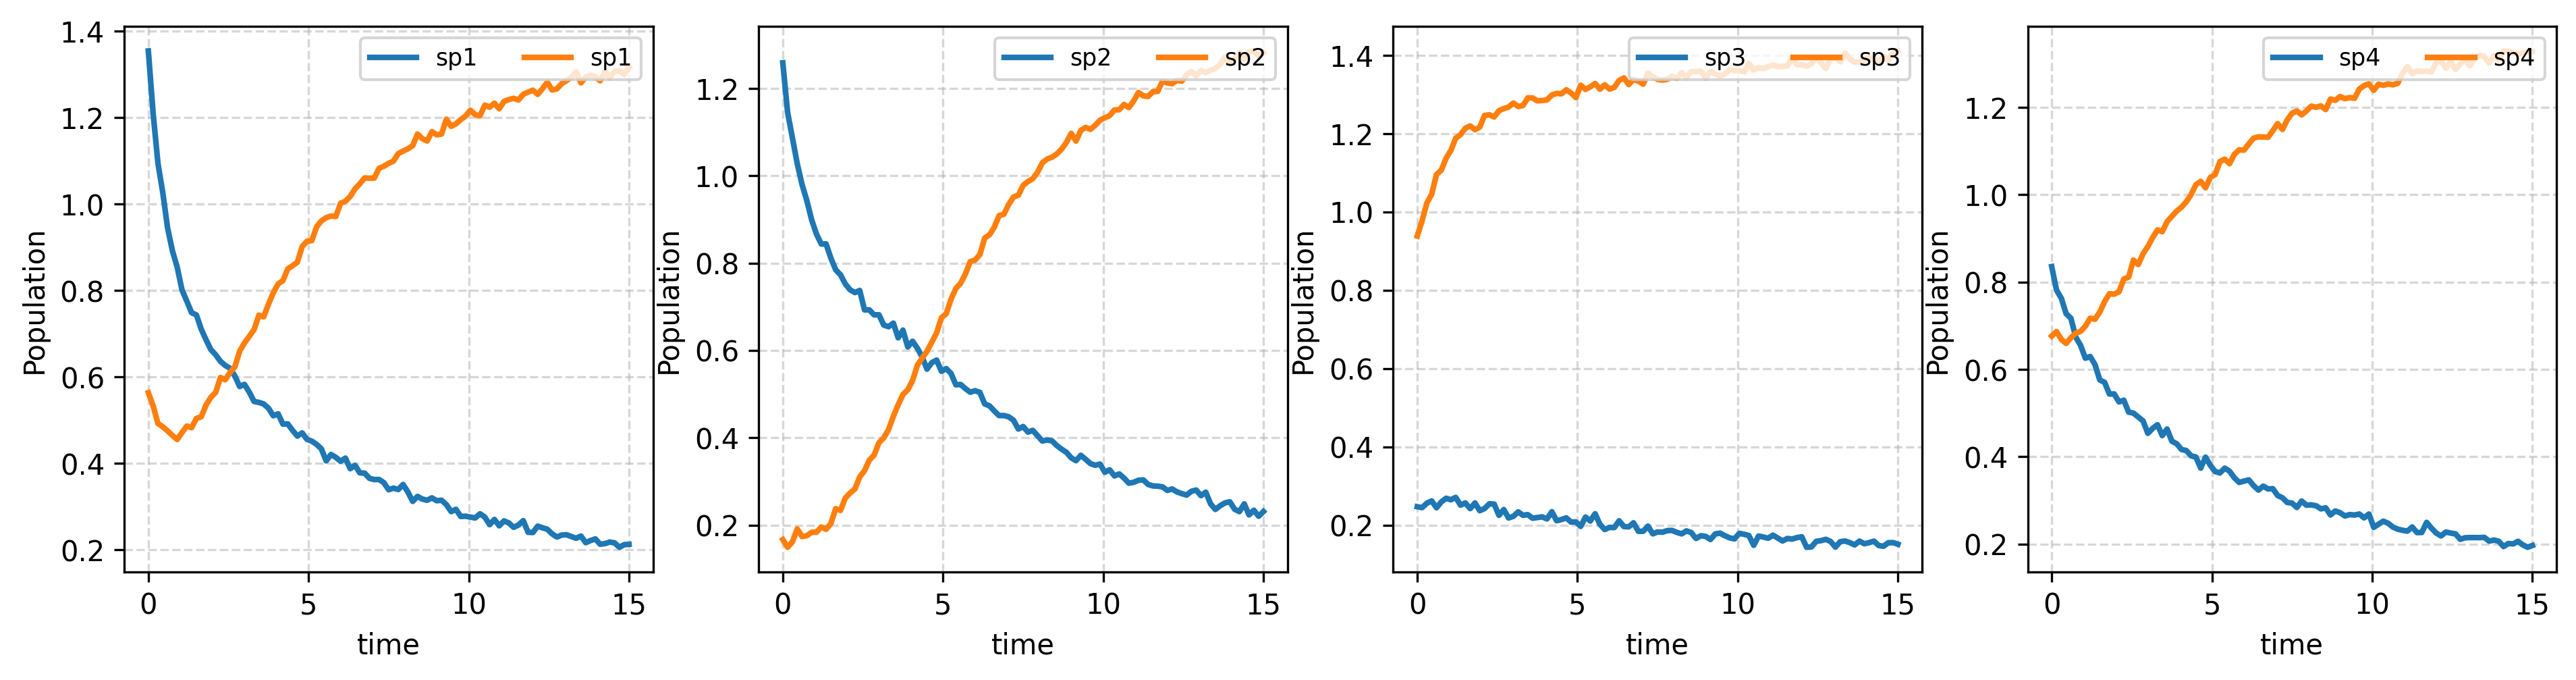

In [14]:
# Community parameters
n_species = 2                # Number of species
r_mean = 1.0                 # Mean value of the intrinsic growth rates
r_std = 0.8                  # Standard dev of the intrinsic growth rates
A_mean = 0.0                 # Mean value of the interaction coefficients
A_std = 0.5                  # Standard dev of the interaction coefficients
sparsity = 0.3               # % of off-diagonal interactions set to zero (optional)
self_reg_strength = 1.0      # Diagonal set to -1.0 (self-regulation)
RSEED = 6                    # Random Seed
T = 15.0                     # Simulated time

# Define interaction matrix
r_gt, A_gt = generate_glv(n = n_species, r_mean=r_mean, r_std=r_std,
                    A_mean=A_mean, A_std=A_std,
                    sparsity=sparsity,
                    self_reg_strength=self_reg_strength,
                    seed=RSEED,
                    uniform=False)

# Initial conditions: small positive random densities
num_init_cond = 4
x0_list = []
rng = np.random.RandomState(6)
for i in range(num_init_cond):
    x0_list.append(rng.uniform(low=0.1, high=1.5, size=(n_species,)))

# Numerical integration parameters
t_0 = 0                          # a
t_f = T                          # b
t_step = 0.15                     # h
t_total_steps = int((t_f-t_0)/t_step)  # k

# Integrate
w_data = []
for i in range(num_init_cond):
    t, w_data_k = integrador_ode(rk4, glv, xa=x0_list[i], t_0=t_0, t_f=t_f, t_total_steps=t_total_steps, p=[r_gt, A_gt])
    w_data.append(w_data_k)
w_data = np.array(w_data)

# Adding noise to simulations
noise_amplitude = 0.04
np.random.seed(42)
for i in range(num_init_cond):
    w_data[i] = w_data[i] + np.random.normal(0, 0.2, w_data[i].shape) * noise_amplitude

# Compute the derivative of the simulated data
w_data_dot=[]
for i in range(num_init_cond):
    gradients = []
    for j in range(n_species):
        gradients.append(np.gradient(w_data[i][:, j], t))
    w_data_dot_k = np.column_stack(gradients)
    w_data_dot.append(w_data_dot_k)
w_data_dot = np.array(w_data_dot)

# Display some outputs and a plot (single figure, multiple species lines)
print(f"n_species = {n_species}, time steps = {len(t)}, noise = {noise_amplitude*100}%")

# Plot time series

fig, ax = plt.subplots(1,num_init_cond, figsize=(15.5,3.5), dpi=300)
for i in range(num_init_cond):
    for j in range(n_species):
        ax[i].plot(t, w_data[i][:, j], label=f"sp{i+1}", lw=2)
        ax[i].set_xlabel("time")
        ax[i].set_ylabel("Population")
        ax[i].legend(loc='upper right', fontsize='small', ncol=2)
        ax[i].grid(True, alpha=0.5, linestyle='--')
plt.show()

Interaction Matrix: 
[[-1.         -0.4495459 ]
 [-1.24339033 -1.        ]]

Growth Rates: 
[0.75057306 1.58320314]


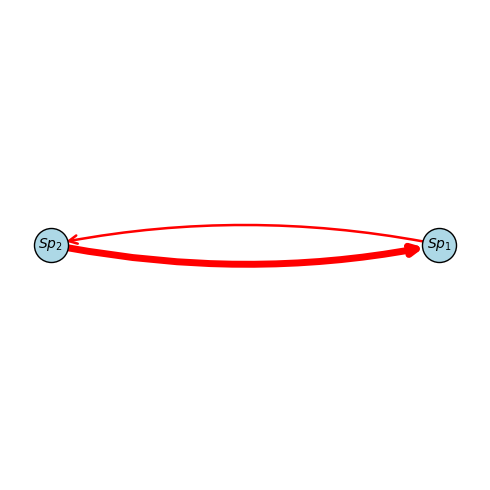

In [15]:
print(f"Interaction Matrix: \n{A_gt}\n")
print(f"Growth Rates: \n{r_gt}")
node_labels = {n: rf"$Sp_{n+1}$" for n in range(n_species)}
plot_interaction_graph(A_gt, node_labels, n_species)

# Separate simulated data into training and testing datasets

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Use MinMax scaler on the time variable ([0, T] -> [0,1])
scaler_t = MinMaxScaler()
t_data_minmax = scaler_t.fit_transform(t.reshape(-1,1))
t_data_minmax = t.reshape(-1,1)

# Transform time series simulated data to Tensors for training
t_data = torch.tensor(t_data_minmax, dtype=torch.float32).to(device) 
X_data = torch.tensor(w_data, dtype=torch.float32).to(device)

# Train-Test split for simulated data (80-20)
test_split_size = 0.2
X_data_train_ICs = torch.Tensor(size=(num_init_cond, int(len(t)*(1-test_split_size)),n_species)).to(device)
X_data_valid_ICs = torch.Tensor(size=(num_init_cond, int(len(t)*test_split_size)+1,n_species)).to(device)
t_data_train_ICs = torch.Tensor(size=(num_init_cond, int(len(t)*(1-test_split_size)))).to(device)
t_data_valid_ICs = torch.Tensor(size=(num_init_cond, int(len(t)*test_split_size)+1)).to(device)

for i in range(X_data.shape[0]):
    t_data_train_k, t_data_valid_k, X_data_train_k, X_data_valid_k = train_test_split(t_data, X_data[i], test_size=test_split_size, shuffle=False)
    X_data_train_ICs[i] = X_data_train_k
    X_data_valid_ICs[i] = X_data_valid_k
    t_data_train_ICs[i] = t_data_train_k.T
    t_data_valid_ICs[i] = t_data_valid_k.T


# Defining the colocation points
t_colocation = torch.linspace(t_data_minmax.min(), t_data_minmax.max(), 1000).reshape(-1, 1) # Colocation points of shape (1000,1)
t_colocation = t_colocation.requires_grad_().to(device) 

# Train-Validation split of the colocation points (80-20)
# Compute the ground truth (r, A) as a re-indexed representation of Xi in a polynomial basis
def transform_Xi_into_A_r(Xi, n_species, degree):
    '''
    Inverse of transform_A_r_into_Xi().
    Given a coefficient matrix Xi, extracts the intrinsic growth vector r
    and the interaction matrix A for a gLV system.

    Inputs:
        - Xi:        Coefficient matrix  - R^(m, n_species)
                     (can be numpy array or torch.Tensor)
        - n_species: Number of species   - int
        - degree:    Polynomial degree   - int  (must be >= 2)

    Returns:
        - r: Intrinsic growth vector     - same type as Xi, shape (n_species,)
        - A: Interaction matrix          - same type as Xi, shape (n_species, n_species)
    '''
    is_tensor = isinstance(Xi, torch.Tensor)

    if is_tensor:
        r = torch.zeros(n_species, dtype=Xi.dtype, device=Xi.device)
        A = torch.zeros((n_species, n_species), dtype=Xi.dtype, device=Xi.device)
    else:
        r = np.zeros(n_species)
        A = np.zeros((n_species, n_species))

    # Precompute interaction pairs (p < q) — must match transform_A_r_into_Xi
    pairs = [(p, q) for p in range(n_species) for q in range(p+1, n_species)]

    for i in range(Xi.shape[0]):

        if i < n_species:                       # x_i terms -> r[i]
            r[i] = Xi[i, i]

        elif i < 2 * n_species:                 # x_i^2 terms -> A[k, k]
            k = i - n_species
            A[k, k] = Xi[i, k]

        else:                                   # x_p * x_q terms -> A[p,q] and A[q,p]
            interaction_row = i - 2 * n_species
            p, q = pairs[interaction_row]
            A[p, q] = Xi[i, p]
            A[q, p] = Xi[i, q]

    return r, A
t_coloc_train, t_coloc_valid = train_test_split(t_colocation, test_size=0.2, shuffle=True)
# Make the training collocation points a leaf tensor, so each epoch builds its own graph (no retain_graph needed)
t_coloc_train = t_coloc_train.detach().requires_grad_()

Using device: cuda


# Training and network inference

In [17]:
np.random.seed(42)
torch.manual_seed(42)

# Number of potential polynomial terms up to order 'd'
d = 2
n_terms = number_of_polynomial_terms(n_vars=n_species, degree=d)

# Random initialization of r and A, and, hence Xi
r = np.random.uniform(low=-4, high=4, size=r_gt.shape)
A = np.random.uniform(low=-4, high=4, size=A_gt.shape)

# Transform into tensors
r_tensor = torch.tensor(r, dtype = torch.float32, requires_grad = True, device=device)
A_tensor = torch.tensor(A, dtype = torch.float32, requires_grad = True, device=device)

# Compute Xi and ground truth Xi as a re-index of (r, A) and (r_gr, A_gt)
Xi = transform_A_r_into_Xi(r, A, n_species, d)
Xi_ground_truth = transform_A_r_into_Xi(r_gt, A_gt, n_species, d)

# Initialize weights for the loss function terms
alpha = physics_loss_weight(w_data, w_data_dot, t)
beta = 5e-7

# Dictionary for saving values during training
control_data = {'trained_networks'      :    [],
                'training_data'         :    [],
                'validation_data'       :    [],
                'Xi_over_training'      :    [],
                'loss_train_per_epoch'  :    [], # This contains loss_train for each PINN per epoch
                'loss_valid_per_epoch'  :    [], # This contains loss_valid for each PINN per epoch
                'loss_phys_per_epoch'   :    [], # This contains loss_physics for each PINN per epoch
                'loss_ic_per_epoch'     :    [], # This contains loss_ic for each PINN per epoch
                'loss_train_total_epoch':    [], # This contains the SUM of loss_train across PINNs per epoch
                'loss_valid_total_epoch':    [], # This contains the SUM of loss_valid across PINNs per epoch
                'loss_phys_total_epoch' :    [], # This contains the SUM of loss_physics across PINNs per epoch
                'loss_ic_total_epoch'   :    [], # This contains the SUM of loss_ic across PINNs per epoch
                'loss_reg_epoch'        :    [],
                'total_losses'          :    [],
                'simulated_r'           :    [],
                'simulated_A'           :    [],
                'simulated_init_cond'   :    [],
                'simulated_data'        :    [],
                'simulated_data_t'      :    [],
                'simulated_data_dot'    :    [],
                'Xi_ground_truth'       :    [],
                'numeric_integr_param'  :    [],
                'noise_amplitude'       :    []
                }

# Empty arrays for saving values across epochs
Xi_history = []
Xi_history.append(Xi)
loss_train_per_epoch   = []   # List of length epochs, each entry = list of length num_IC
loss_valid_per_epoch   = []
loss_phys_per_epoch    = []
loss_ic_per_epoch      = []
loss_train_total_epoch = []   # Scalar per epoch
loss_valid_total_epoch = []
loss_phys_total_epoch  = []
loss_ic_total_epoch    = []
loss_reg_epoch         = []
total_losses           = []

# Save simulated data
control_data['simulated_data'].append(w_data)
control_data['simulated_data_t'].append(t)
control_data['simulated_data_dot'].append(w_data_dot)
control_data['simulated_init_cond'].append(x0_list)
control_data['simulated_A'].append(A)
control_data['simulated_r'].append(r)
control_data['Xi_ground_truth'].append(Xi_ground_truth)
control_data['numeric_integr_param'].append(dict({'t_0': t_0, 't_f' : t_f, 't_step' :t_step, 'k': t_total_steps}))
control_data['noise_amplitude'].append(noise_amplitude)

# Training hyperparameters
#   Phase 1 [0, warmup_epochs):         data only (w_phys = 0); PINNs learn the trajectories
#   At warmup_epochs:                    (r, A) reset by least squares on the PINNs' outputs and derivatives
#   Phase 2 [warmup_epochs, ramp_end):  physics weight ramps geometrically from alpha*alpha_start to alpha*alpha_end
#   Phase 3 [ramp_end, epochs):          physics weight held; PINN and (r, A) learning rates decay to their minimum
epochs = 10000
warmup_epochs = 2000
ramp_end = 7000
alpha_start, alpha_end = 1e-4, 1e-1  # Multipliers of alpha at the start and the end of the ramp
lr_net, lr_net_min = 1e-3, 1e-5      # PINNs: constant during warm-up, cosine decay afterwards
lr_xi, lr_xi_min = 1e-3, 1e-5        # (r, A): cosine decay over the whole run
lock_epoch = epochs # PINNs are never locked: their learning rate decays to lr_net_min instead

# Physics loss weight multiplier per epoch
def alpha_schedule(epoch):
    if epoch < warmup_epochs:
        return 0.0
    p = min(1.0, (epoch - warmup_epochs) / (ramp_end - warmup_epochs))
    return alpha_start * (alpha_end / alpha_start) ** p

# PINNs learning rate factor per epoch (relative to lr_net)
def net_lr_factor(epoch):
    if epoch <= warmup_epochs:
        return 1.0
    p = (epoch - warmup_epochs) / (epochs - warmup_epochs)
    return (lr_net_min + 0.5 * (lr_net - lr_net_min) * (1 + np.cos(np.pi * p))) / lr_net

# Initialize one PINN and respective Optimizer per IC
nets = []
nets_optimizers = []
nets_schedulers = []
for i in range(num_init_cond):
    pinn_model = PINN(n_input=1, n_output=n_species, n_hidden=3).to(device)
    optimizer_net = torch.optim.Adam(list(pinn_model.parameters()), lr=lr_net)
    scheduler_net = torch.optim.lr_scheduler.LambdaLR(optimizer_net, net_lr_factor)
    nets.append(pinn_model)
    nets_optimizers.append(optimizer_net)
    nets_schedulers.append(scheduler_net)

# Initialize optimizer for shared parameters across PINNs
optimizer_xi  = torch.optim.Adam([r_tensor, A_tensor], lr=lr_xi)
scheduler_xi  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_xi, T_max=epochs, eta_min=lr_xi_min)

# Initialize loss function
loss_fn = nn.MSELoss()

for i, epoch in tqdm_notebook(enumerate(np.arange(epochs)), desc = 'Training', total = len(np.arange(epochs))):

    # End of the data-only phase: set (r, A) to their least-squares values for the current PINNs
    if epoch == warmup_epochs:
        r_ls, A_ls = lstsq_r_A(nets, t_coloc_train, n_species)
        with torch.no_grad():
            r_tensor.copy_(torch.as_tensor(r_ls, dtype=torch.float32, device=device))
            A_tensor.copy_(torch.as_tensor(A_ls, dtype=torch.float32, device=device))
        optimizer_xi.state.clear() # Forget the Adam moments accumulated before the reset

    # Physics loss weight for this epoch
    w_phys = alpha * alpha_schedule(epoch)
    
    # For saving losses per PINN per epoch 
    loss_train_k_list = []
    loss_phys_k_list  = []
    loss_ic_k_list    = []
    loss = 0

    for k in range(num_init_cond):

        # Unpack the k-th IC and its respective PINN, optimizers and schedulers
        pinn_model = nets[k]
        optimizer_net = nets_optimizers[k]
        scheduler_net = nets_schedulers[k]
        optimizer_net.zero_grad()
        optimizer_xi.zero_grad()

        # Unpack training data for the k-th IC
        X_data_train = X_data_train_ICs[k]
        t_data_train = t_data_train_ICs[k].reshape(-1,1)
        X_data_train_IC = X_data_train_ICs[k][0,:]

        # ==================================================
        # TRAIN PINNs ON DATA
        # ==================================================
        pinn_model.train()

        # Compute data loss
        X_pred = pinn_model(t_data_train)
        loss_train = loss_fn(X_data_train, X_pred)

        # Predict over colocation points
        X_coloc_pred = pinn_model(t_coloc_train)

        # Predict initial condition
        X_pred_IC = pinn_model(t_colocation[0])

        # Compute IC loss term
        loss_ic = loss_fn(X_pred_IC, X_data_train_IC)

        # ==================================================
        # TRAIN Xi 
        # ==================================================

        # Compute the gradient w.r.t. the input with autograd
        dX_dt_pred = torch.zeros_like(X_coloc_pred)
        for i in range(X_coloc_pred.shape[1]):
            x_pred = X_coloc_pred[:,i]
            dX_dt_pred[:,i] = torch.autograd.grad(x_pred, t_coloc_train, grad_outputs=torch.ones_like(x_pred), create_graph=True)[0].squeeze()
    
        # Compute the library of functions using the colocation points
        Theta_tensor = library_poly_torch(X_coloc_pred, d)

        # Compute physics loss
        residual = dX_dt_pred - glv_tensor(X_coloc_pred, t=None, p=[r_tensor, A_tensor])
        loss_physics = torch.mean(residual**2)

        # Save training loss, physics loss and IC loss
        loss_train_k_list.append(loss_train.item())
        loss_phys_k_list.append(loss_physics.item())
        loss_ic_k_list.append(loss_ic.item())
        # Compute total loss
        loss_k = loss_train + w_phys * loss_physics + loss_ic

        # Sum all losses from every PINN corresponding to each IC
        loss += loss_k

    # Compute total training loss, total physics loss and total IC loss
    loss_train_total = np.stack(loss_train_k_list).sum()
    loss_phys_total  = np.stack(loss_phys_k_list).sum()
    loss_ic_total    = np.stack(loss_ic_k_list).sum()

    # Compute regularization term
    loss_reg = torch.linalg.matrix_norm(A_tensor, ord=1) # ord: ['fro', 1] --- Frobenius or L1 norm
    loss += beta * loss_reg

    # Backpropagation
    loss.backward()

    # Update Xi coefficients
    optimizer_xi.step()
    scheduler_xi.step()

    # Update PINNs parameters until lock_epoch
    for k in range(num_init_cond):
        optimizer_net = nets_optimizers[k]
        scheduler_net = nets_schedulers[k]
        if epoch <= lock_epoch:
            optimizer_net.step()
            scheduler_net.step()

    # ==================================================
    # VALIDATE PINNs ON DATA
    # ==================================================

    loss_valid_k_list = []
    for k in range(num_init_cond):

        # Unpack the k-th IC and its respective PINN, optimizers and schedulers
        pinn_model = nets[k]
        pinn_model.eval()

        # Unpack validation data for the k-th IC
        X_data_valid = X_data_valid_ICs[k]
        t_data_valid = t_data_valid_ICs[k].reshape(-1,1)        
        
        # Predict and evaluate loss
        X_pred_valid = pinn_model(t_data_valid)
        loss_valid = loss_fn(X_pred_valid, X_data_valid)

        # Save validation loss value
        loss_valid_k_list.append(loss_valid.item())

    loss_valid_total = np.stack(loss_valid_k_list).sum()

    # ==================================================
    # Save progress
    # ==================================================

    # Save losses values over training
    loss_train_per_epoch.append([lt for lt in loss_train_k_list])   # Save training loss per PINN
    loss_valid_per_epoch.append([lt for lt in loss_valid_k_list])   # Save validation loss per PINN
    loss_phys_per_epoch.append([lp for lp in loss_phys_k_list])     # Save physics loss per PINN
    loss_ic_per_epoch.append([lic for lic in loss_ic_k_list])       # Save IC loss per PINN
    loss_train_total_epoch.append(loss_train_total.item())          # Save total training loss
    loss_valid_total_epoch.append(loss_valid_total.item())          # Save total validation loss
    loss_phys_total_epoch.append(loss_phys_total.item())            # Save total physics loss
    loss_ic_total_epoch.append(loss_ic_total.item())                # Save total IC loss
    loss_reg_epoch.append(loss_reg.item())                          # Save total regularization loss
    total_losses.append(loss.item())

    # Compute Xi as a re-index of (r, A)
    Xi = transform_A_r_into_Xi(r_tensor, A_tensor, n_species=n_species, degree=d)
    Xi_history.append(Xi)

# Data in a dictionary
control_data['Xi_over_training'].append(Xi_history)
control_data['loss_train_per_epoch'].append(loss_train_per_epoch)
control_data['loss_valid_per_epoch'].append(loss_valid_per_epoch)
control_data['loss_phys_per_epoch'].append(loss_phys_per_epoch)
control_data['loss_ic_per_epoch'].append(loss_ic_per_epoch)
control_data['loss_train_total_epoch'].append(loss_train_total_epoch)
control_data['loss_valid_total_epoch'].append(loss_valid_total_epoch)
control_data['loss_phys_total_epoch'].append(loss_phys_total_epoch)
control_data['loss_ic_total_epoch'].append(loss_ic_total_epoch)
control_data['loss_reg_epoch'].append(loss_reg_epoch)
control_data['total_losses'].append(total_losses)

# Save the trained model and data used for training and validation
trained_models = []
training_data = []
validation_data = []

for k in range(num_init_cond):
    # Unpack trained models and data
    trained_model = nets[k]
    X_data_train = X_data_train_ICs[k]
    X_data_valid = X_data_valid_ICs[k]
    t_data_train = t_data_train_ICs[k].reshape(-1,1)
    t_data_valid = t_data_valid_ICs[k].reshape(-1,1)

    # Store trained model
    trained_models.append(trained_model.state_dict())

    # Store training and validation data
    train_sorted_indices = np.argsort(t_data_train.detach().cpu().numpy()[:, 0]) # Sort training data
    valid_sorted_indices = np.argsort(t_data_valid.detach().cpu().numpy()[:, 0]) # Sort validation data
    training_data.append(X_data_train.detach().cpu().numpy()[train_sorted_indices])
    validation_data.append(X_data_valid.detach().cpu().numpy()[valid_sorted_indices])

control_data['trained_networks'].append(trained_models)
control_data['training_data'].append(training_data)
control_data['validation_data'].append(validation_data)

Training:   0%|          | 0/70000 [00:00<?, ?it/s]

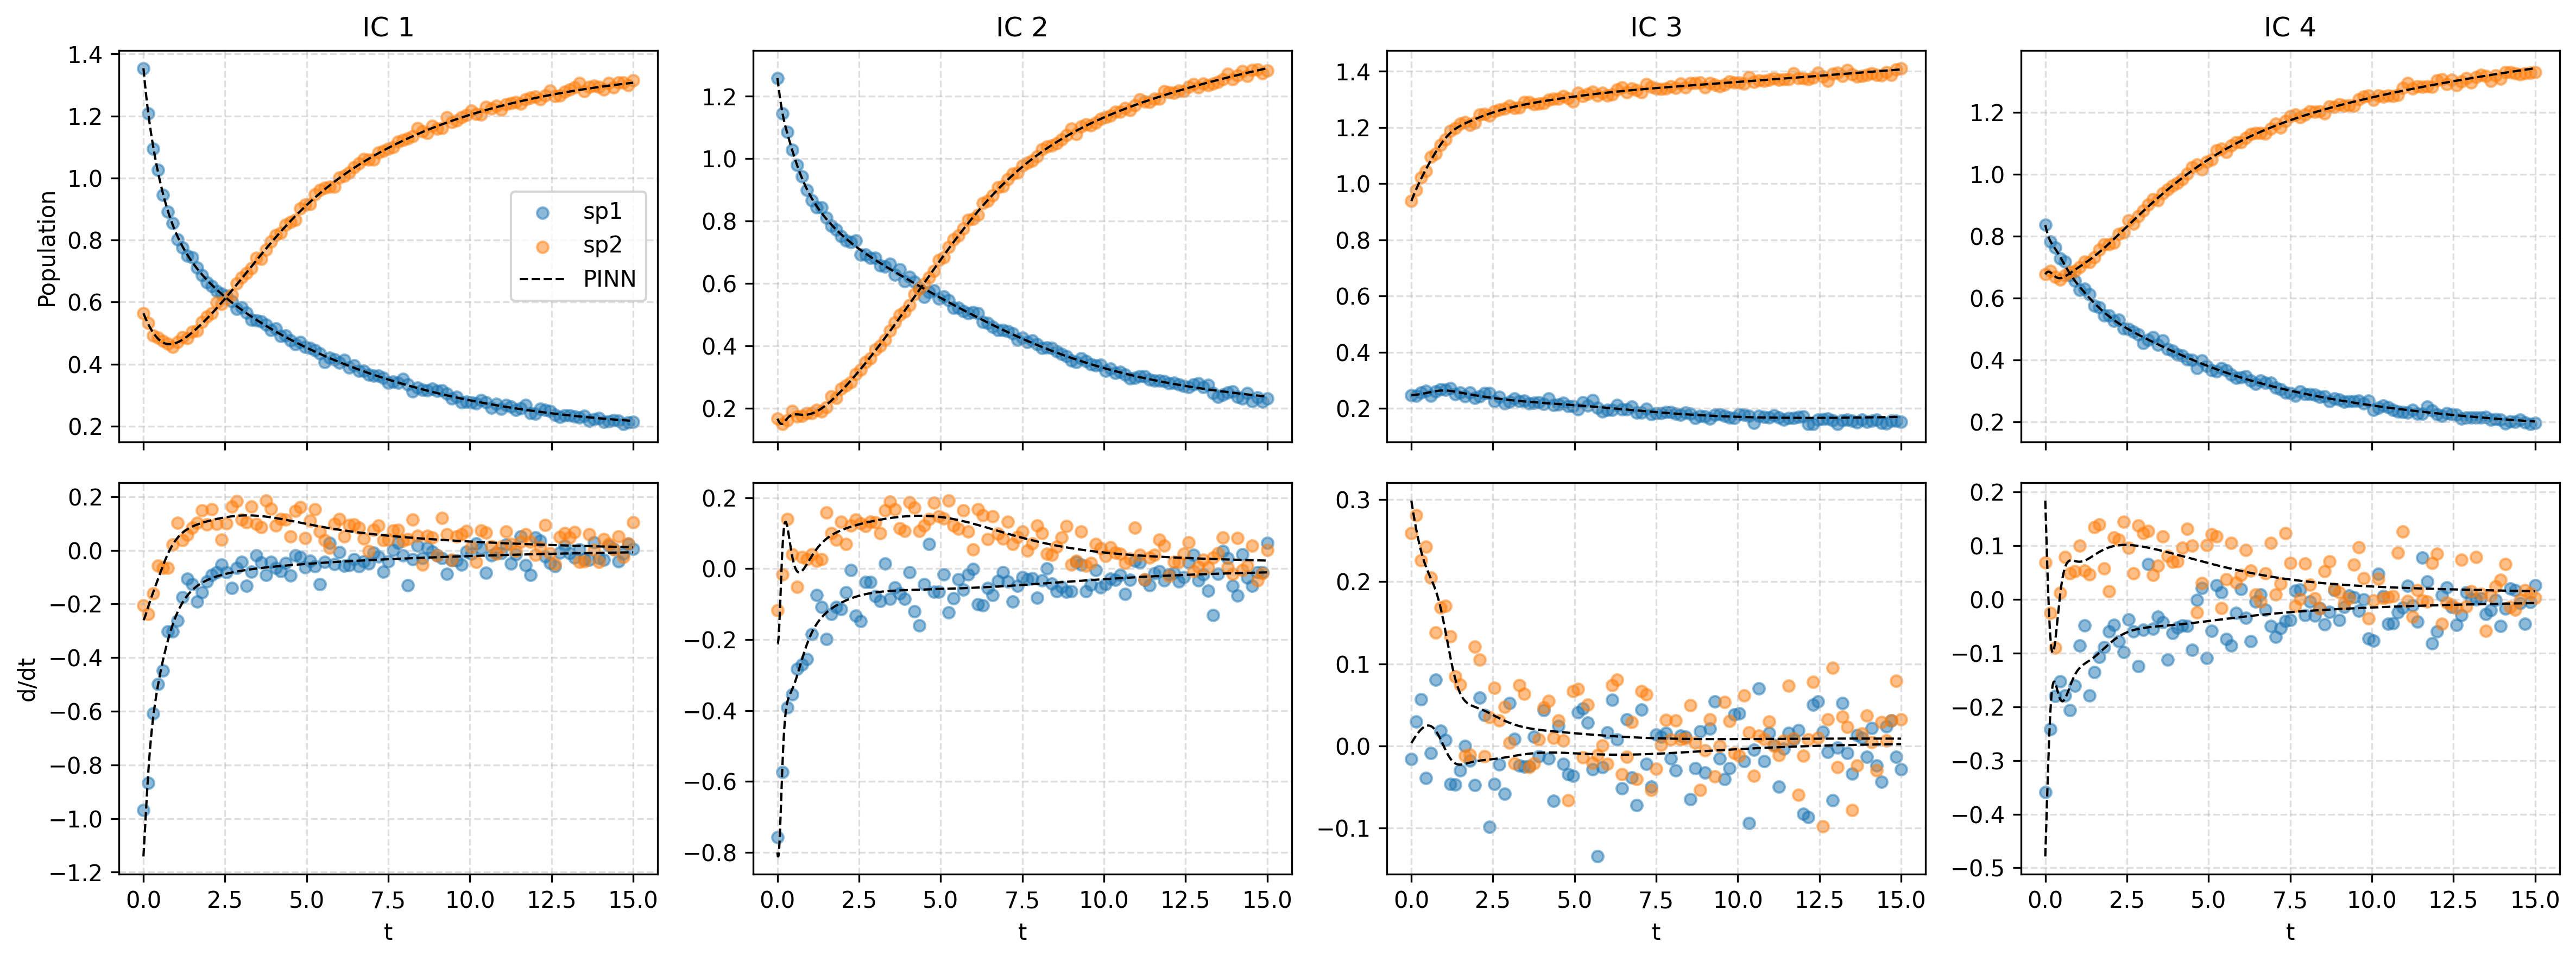

In [18]:
plot_multiIC_pinn_traj_and_deriv(nets, t_colocation, w_data, t_data_minmax, dpi=300)

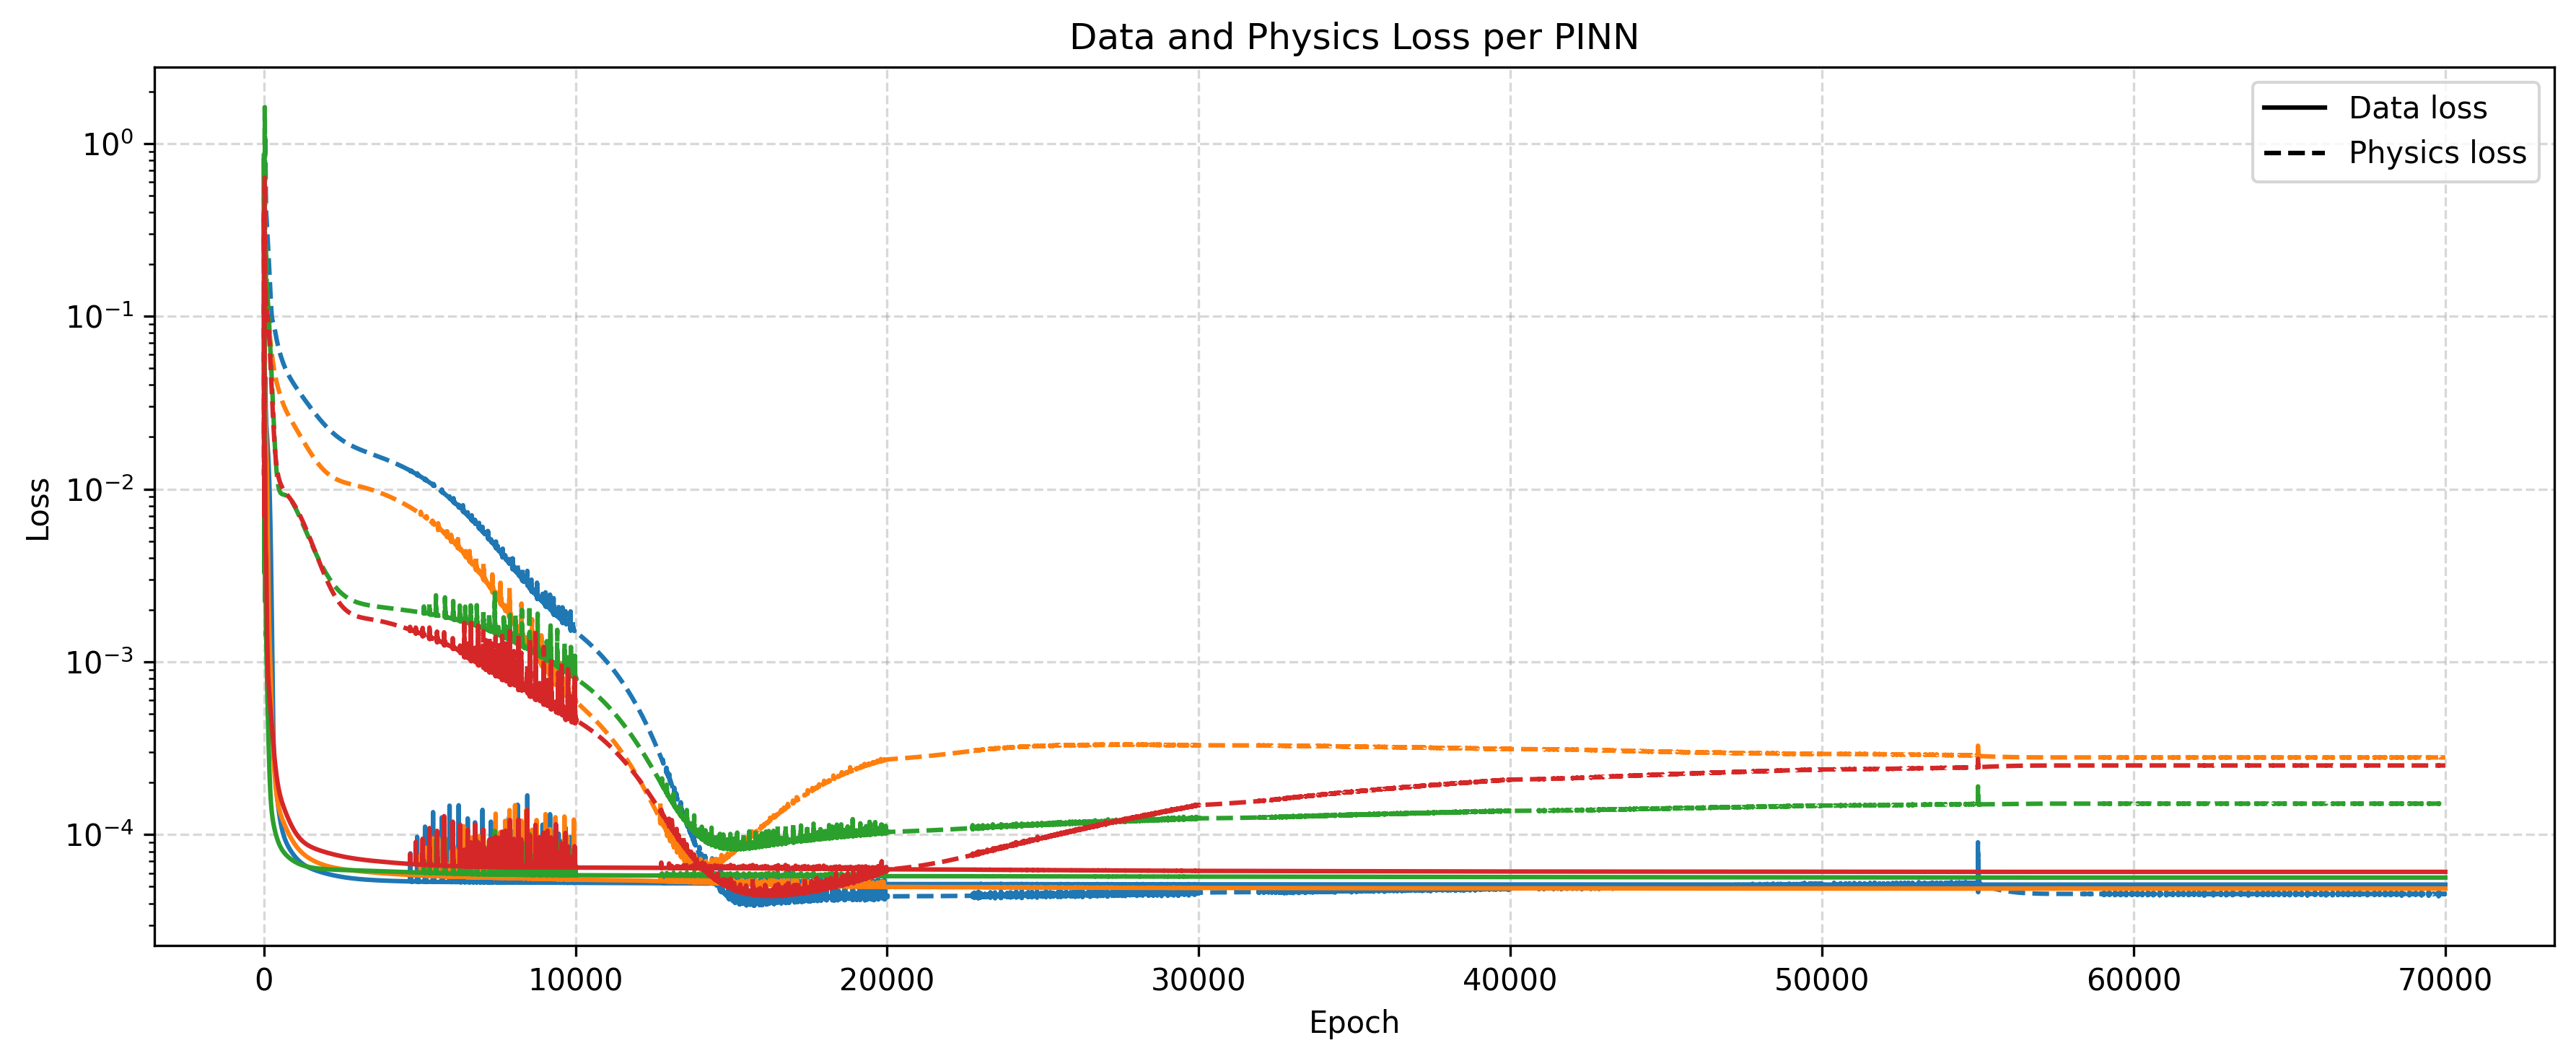

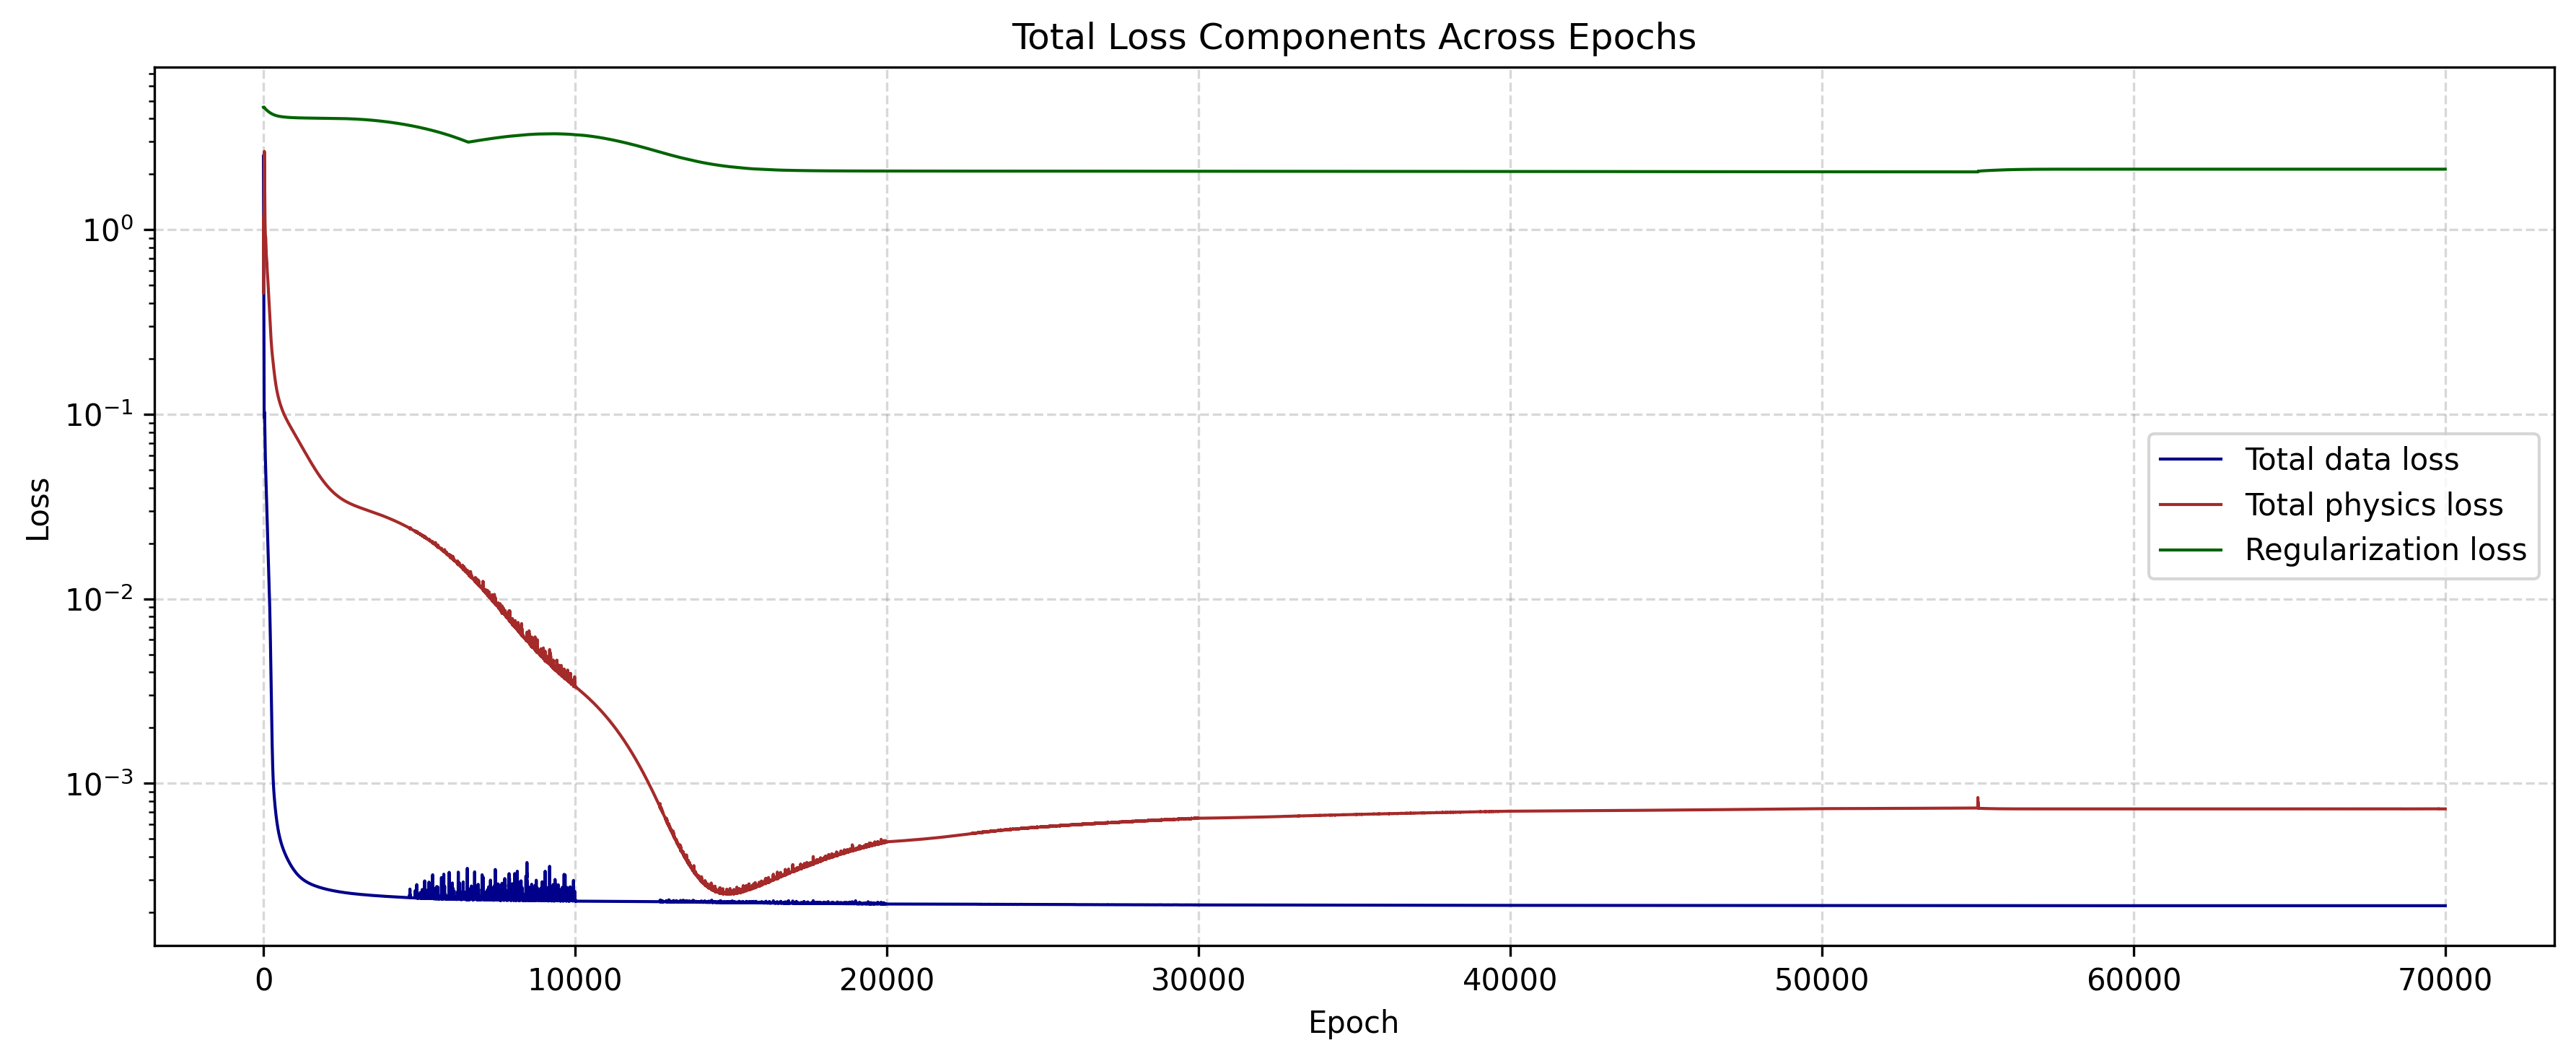

In [19]:
plot_losses_per_pinn(control_data, dpi=300)
plot_losses(control_data, dpi=300)

In [34]:
print(f"Ground Truth: \n{A_gt}")
print(f"Inference: \n{transform_Xi_into_A_r(control_data['Xi_over_training'][0][-1], n_species, degree=2)[1]}")

Ground Truth: 
[[-1.         -0.4495459 ]
 [-1.24339033 -1.        ]]
Inference: 
[[-1.00402701 -0.4433026 ]
 [-1.1236676  -0.91240138]]


In [20]:
# Save data
file_name = f'data_{num_init_cond}_IC_for_STLSq-RSEED_{RSEED}-{n_species}_species-{noise_amplitude * 100}%_noise-{t_data.cpu().detach().numpy().shape[0]-1}_timesteps-{(epochs)/1000:.0f}kEpc-lock_at_{lock_epoch/1000:.0f}k'
#np.save(file_name, control_data)
#print(f"Saved data as: {file_name}.npy")